<a href="https://colab.research.google.com/github/mpjnss/Modelagem-Computacional/blob/main/Atividade_dia_19_10_Modelagem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q ultralytics opencv-python

from ultralytics import SAM
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from google.colab import drive


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
# 1. Montar o Google Drive e carregar a imagem
drive.mount('/content/drive')
caminho_imagem = "/content/drive/MyDrive/Colab Notebooks/Modelagem /revap.avif"

imagem_bgr = cv2.imread(caminho_imagem)
assert imagem_bgr is not None, f"Imagem não encontrada em: {caminho_imagem}"
imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# 2. Carregar o modelo SAM 2
modelo_sam = SAM("sam2_b.pt")

In [5]:
# 3. Função auxiliar para plotar lado a lado: Original + Prompts | Máscara Binária | Máscara Sobreposta
def avaliar_prompt_sam(titulo, bboxes=None, points=None, labels=None):
    resultados = modelo_sam(caminho_imagem, bboxes=bboxes, points=points, labels=labels, verbose=False)

    # Extrai a máscara binária (0 = fundo, 1 = objeto segmentado)
    mascara_binaria = resultados[0].masks.data[0].cpu().numpy().astype(np.uint8)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(titulo, fontsize=14, fontweight='bold')

    # Painel 1: Imagem Original + visualização dos Prompts utilizados
    axes[0].imshow(imagem_rgb)
    axes[0].set_title("1. Imagem Original + Prompts")
    if bboxes is not None:
        for box in bboxes:
            x1, y1, x2, y2 = box
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor='yellow', facecolor='none', label='Caixa (bbox)')
            axes[0].add_patch(rect)
    if points is not None and labels is not None:
        pts = np.array(points[0])
        lbs = np.array(labels[0])
        pos = pts[lbs == 1]
        neg = pts[lbs == 0]
        if len(pos) > 0:
            axes[0].scatter(pos[:, 0], pos[:, 1], c='lime', marker='*', s=200, edgecolors='black', label='Ponto Positivo (1)')
        if len(neg) > 0:
            axes[0].scatter(neg[:, 0], neg[:, 1], c='red', marker='X', s=150, edgecolors='black', label='Ponto Negativo (0)')
    axes[0].legend(loc='lower left')
    axes[0].axis('off')

    # Painel 2: Máscara Binária (Preto e Branco)
    axes[1].imshow(mascara_binaria, cmap='gray')
    axes[1].set_title("2. Máscara Binária")
    axes[1].axis('off')

    # Painel 3: Máscara Sobreposta à Imagem
    sobreposta = imagem_rgb.copy()
    cor_mascara = np.array([0, 180, 255], dtype=np.uint8) # Azul claro para destacar na fumaça preta
    sobreposta[mascara_binaria == 1] = (0.5 * sobreposta[mascara_binaria == 1] + 0.5 * cor_mascara).astype(np.uint8)
    axes[2].imshow(sobreposta)
    axes[2].set_title("3. Máscara Sobreposta")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

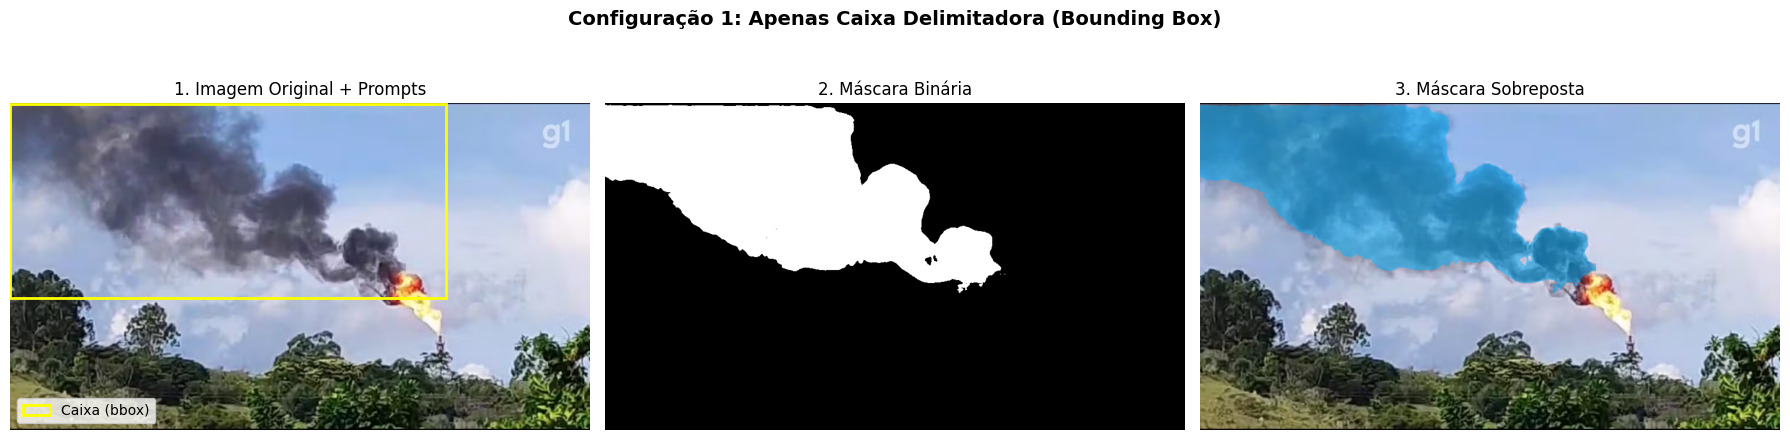

In [6]:
# Configuração 1: Caixa delimitadora cobrindo a região da pluma (do topo esquerdo até a ponta da chaminé)
avaliar_prompt_sam(
    titulo="Configuração 1: Apenas Caixa Delimitadora (Bounding Box)",
    bboxes=[[0, 0, 740, 330]]
)


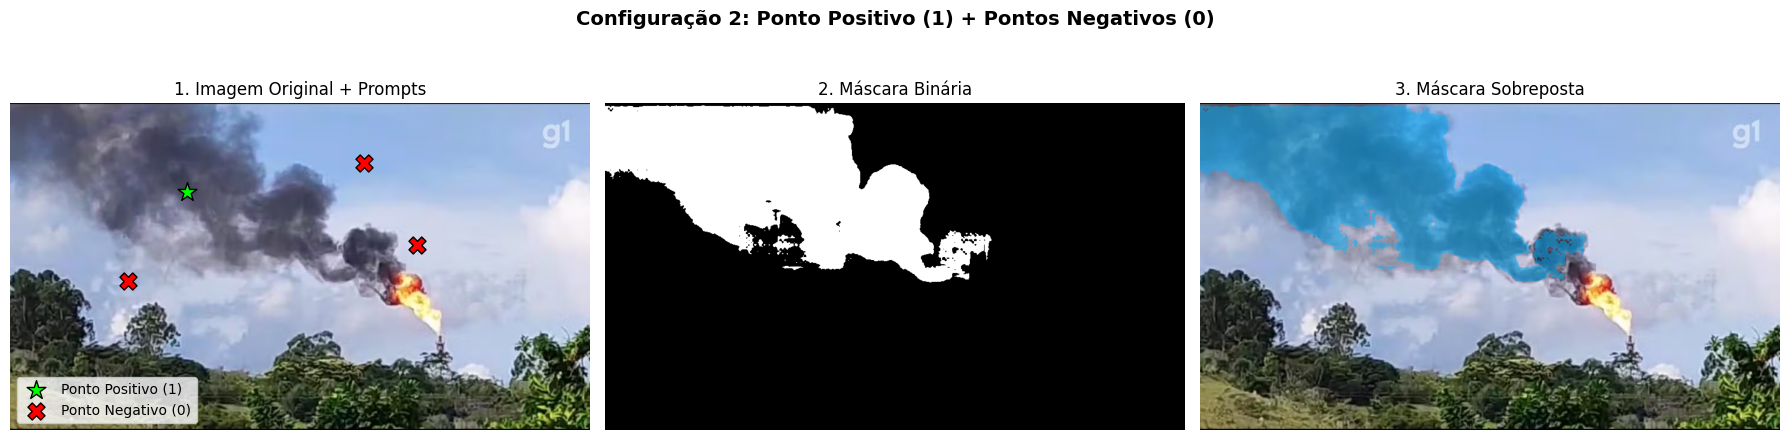

In [7]:
# Configuração 2: 1 Ponto Positivo no centro da fumaça + Pontos Negativos no céu, nuvens e chama
avaliar_prompt_sam(
    titulo="Configuração 2: Ponto Positivo (1) + Pontos Negativos (0)",
    points=[[[300, 150], [600, 100], [200, 300], [690, 240]]],
    labels=[[1, 0, 0, 0]]
)


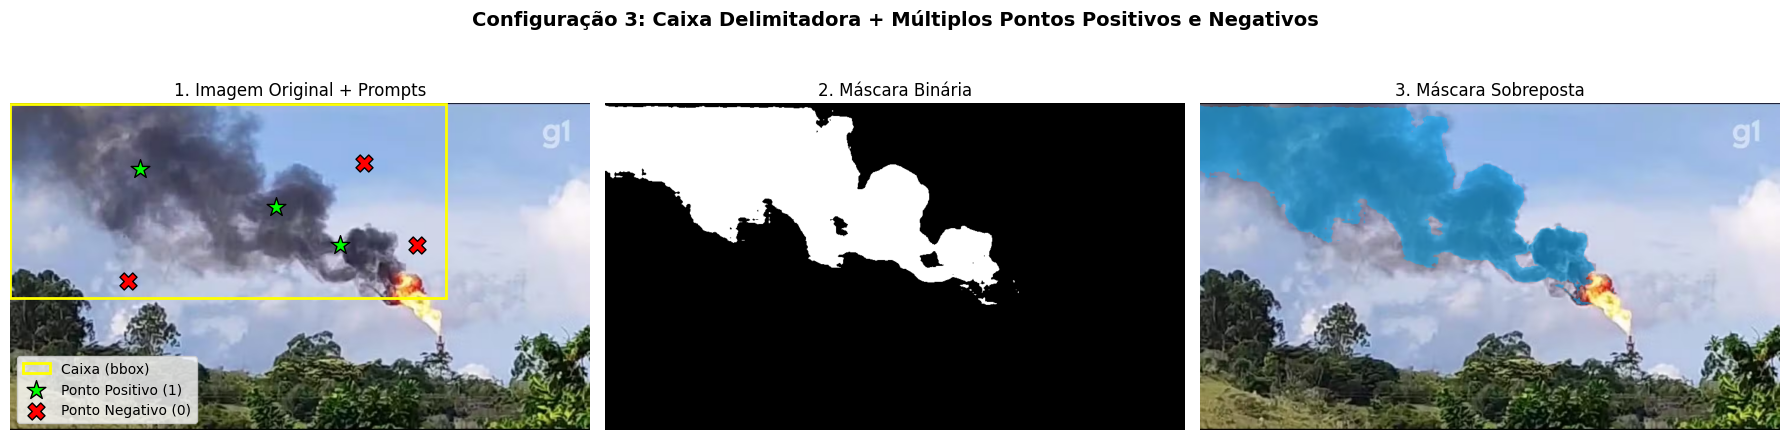

In [8]:
# Configuração 3: Caixa Delimitadora + Múltiplos Pontos Positivos ao longo da pluma + Pontos Negativos
avaliar_prompt_sam(
    titulo="Configuração 3: Caixa Delimitadora + Múltiplos Pontos Positivos e Negativos",
    bboxes=[[0, 0, 740, 330]],
    points=[[[220, 110], [450, 175], [560, 240], [600, 100], [200, 300], [690, 240]]],
    labels=[[1, 1, 1, 0, 0, 0]]
)

## Avaliação dos Resultados e Discussão

### 1. Avaliação das Máscaras e Comparação entre as 3 Configurações de Prompts
* **Configuração 1 (Apenas Caixa Delimitadora):** A máscara cobriu todo o núcleo denso da pluma e parou antes da chama incandescente, mas **incluiu regiões que não pertencem à fumaça**, vazando para uma grande faixa de céu e nuvens acinzentadas na parte inferior esquerda da caixa (acima da copa das árvores).
* **Configuração 2 (1 Ponto Positivo + 3 Pontos Negativos):** A inclusão do ponto negativo (`label=0`) na parte inferior esquerda corrigiu o vazamento sobre as nuvens acima das árvores. Porém, com apenas um ponto positivo no topo da pluma (`[300, 150]`), a máscara apresentou falhas e bordas serrilhadas na região central inferior e próxima à base da tocha, **deixando partes mais diluídas da fumaça de fora**.
* **Configuração 3 (Caixa Delimitadora + 3 Pontos Positivos + 3 Pontos Negativos):** Produziu a segmentação mais precisa. A distribuição de três pontos positivos ao longo do eixo diagonal da pluma preencheu as falhas na região intermediária e na base da fumaça (observadas na Configuração 2), enquanto os pontos negativos e a caixa delimitadora restringiram o fundo, eliminando o falso positivo das nuvens inferiores (observado na Configuração 1). Apenas uma estreita faixa de fumaça muito rarefeita na borda inferior central ficou de fora.

### 2. Quais características da imagem dificultaram a segmentação?
* **Bordas difusas e semitransparência:** Como a pluma sofre dispersão turbulenta no ar, não há uma borda sólida; a concentração de fuligem diminui gradualmente nas extremidades inferiores, tornando a fumaça semitransparente.
* **Transição abrupta na fonte (chama vs. fumaça):** Na ponta da chaminé (tocha/flare), há uma mudança brusca de cor e luminância entre o fogo amarelo-alaranjado e a fumaça preta, exigindo cuidado no posicionamento dos prompts para isolar apenas a pluma de poluentes.

### 3. Como a iluminação, o contraste e a semelhança entre fumaça e nuvens afetaram o resultado?
* **Contraste e Iluminação:** Na borda superior da pluma, a fumaça preta densa apresenta alto contraste contra o céu azul mais limpo, permitindo que o SAM 2 delimite o contorno superior com facilidade nas três configurações.
* **Semelhança entre fumaça diluída e nuvens:** Na parte inferior da pluma, onde a fumaça é mais clara e espalhada pelo vento, a tonalidade acinzentada dos pixels mistura-se visualmente com as nuvens sombreadas ao fundo. Isso explica por que a Configuração 1 uniu a fumaça com as nuvens inferiores em um único bloco e por que, nas Configurações 2 e 3, o modelo precisou excluir a fumaça mais translúcida da borda inferior para não invadir novamente as nuvens.